[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lalvim/DataMining/blob/main/notebooks/unidade_07/07_03_deteccao_multivariada.ipynb)

# Unidade VII — Detecção de *Outliers*

## Detecção multivariada: proximidade, densidade e agrupamento

**Carga estimada:** 2 horas e 30 minutos  
**Pré-requisitos:** caracterização de outliers, métodos univariados, distância, padronização, k-vizinhos, k-means e DBSCAN.

> **Pergunta norteadora:** como priorizar observações incomuns quando os dados têm várias dimensões e regiões com densidades distintas?

Neste notebook, um escore ordena observações para investigação. O orçamento de análise transforma o escore em uma lista de alertas; essa lista não constitui diagnóstico.

## Objetivos de aprendizagem

Ao concluir este notebook, você será capaz de:

- calcular e interpretar a distância ao $k$-ésimo vizinho;
- explicar densidade local alcançável e fator de anomalia local (LOF);
- usar ruído do DBSCAN e distância a centroides como evidências de anomalia;
- comparar detectores sob escala, geometria e densidade diferentes;
- avaliar listas priorizadas com rótulos parciais ou raros;
- comunicar alertas, limitações e decisões de investigação.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import precision_score, recall_score
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 120})

## 1. Cenário sintético com referência conhecida

Construiremos duas regiões normais com densidades diferentes e 18 pontos anômalos. Os rótulos verdadeiros serão guardados apenas para avaliação retrospectiva; os detectores não os recebem durante o ajuste. Em aplicações reais, esses rótulos costumam ser raros, atrasados ou seletivos.

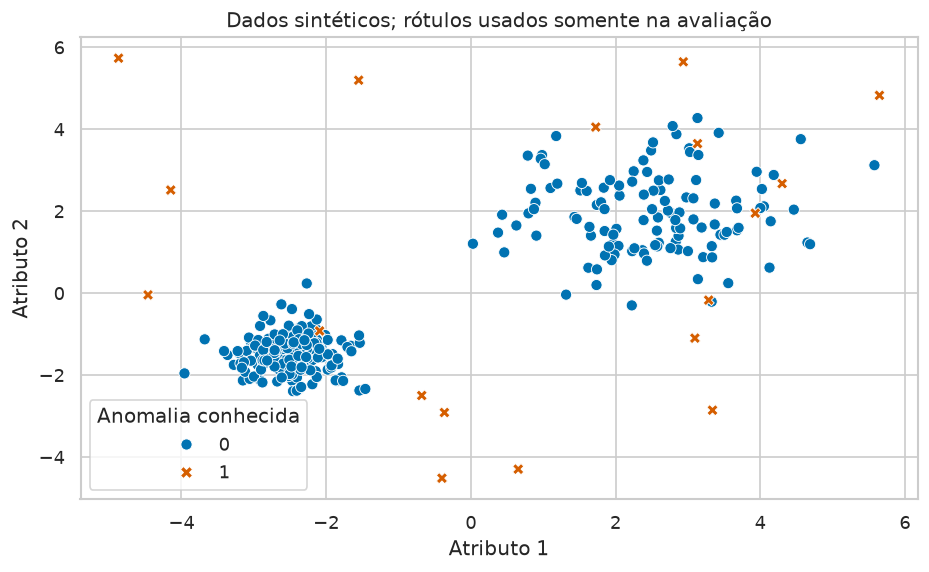

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
X_normal, _ = make_blobs(
    n_samples=[180, 120],
    centers=[(-2.5, -1.5), (2.5, 2.0)],
    cluster_std=[0.45, 1.0],
    random_state=RANDOM_STATE,
)
X_anomalo = rng.uniform(low=[-6, -5], high=[6, 6], size=(18, 2))
X = np.vstack([X_normal, X_anomalo])
y_referencia = np.r_[np.zeros(len(X_normal), dtype=int), np.ones(len(X_anomalo), dtype=int)]
X_pad = StandardScaler().fit_transform(X)
dados = pd.DataFrame(X, columns=["atributo_1", "atributo_2"])
dados["anomalia_referencia"] = y_referencia

ax = sns.scatterplot(
    data=dados, x="atributo_1", y="atributo_2",
    hue="anomalia_referencia", style="anomalia_referencia",
    palette={0: "#0072B2", 1: "#D55E00"}, s=45,
)
ax.set(title="Dados sintéticos; rótulos usados somente na avaliação", xlabel="Atributo 1", ylabel="Atributo 2")
ax.legend(title="Anomalia conhecida")
plt.show()

## 2. Distância ao k-ésimo vizinho

Se $N_k(p)$ contém os $k$ vizinhos mais próximos de $p$, o escore de proximidade pode ser a distância ao vizinho mais distante nesse conjunto:

$$s_k(p)=\max_{o\in N_k(p)}d(p,o).$$

Valores altos indicam isolamento. Um $k$ pequeno reage a detalhes e ruído; um $k$ grande suaviza a vizinhança e pode misturar estruturas. A escala dos atributos define a distância e precisa ser escolhida antes do ajuste.

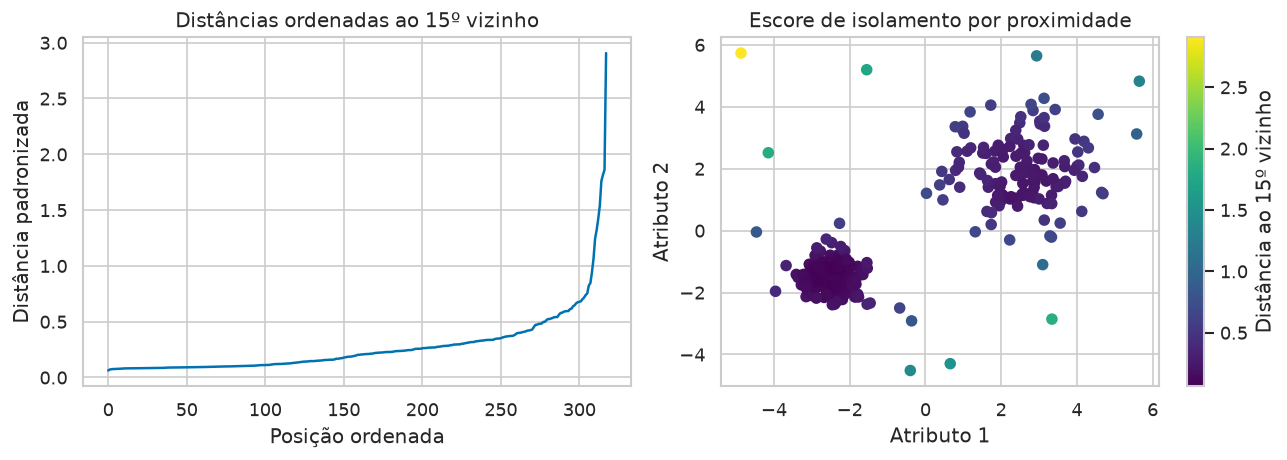

In [3]:
K_VIZINHOS = 15
vizinhos = NearestNeighbors(n_neighbors=K_VIZINHOS + 1).fit(X_pad)
distancias, _ = vizinhos.kneighbors(X_pad)
dados["escore_knn"] = distancias[:, -1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ordem = np.sort(dados["escore_knn"].to_numpy())
axes[0].plot(ordem, color="#0072B2")
axes[0].set(title="Distâncias ordenadas ao 15º vizinho", xlabel="Posição ordenada", ylabel="Distância padronizada")
pontos = axes[1].scatter(X[:, 0], X[:, 1], c=dados["escore_knn"], cmap="viridis", s=35)
axes[1].set(title="Escore de isolamento por proximidade", xlabel="Atributo 1", ylabel="Atributo 2")
fig.colorbar(pontos, ax=axes[1], label="Distância ao 15º vizinho")
fig.tight_layout()
plt.show()

## 3. Fator de anomalia local

O fator de anomalia local (*Local Outlier Factor*, LOF) compara a densidade de $p$ à densidade de seus vizinhos. Primeiro, limita distâncias muito pequenas pela distância-$k$ do vizinho:

$$\operatorname{reach\text{-}dist}_k(p,o)=\max\{d_k(o),d(p,o)\}.$$

A densidade local alcançável é o inverso da média dessas distâncias:

$$\operatorname{lrd}_k(p)=\left(\frac{1}{|N_k(p)|}\sum_{o\in N_k(p)}\operatorname{reach\text{-}dist}_k(p,o)\right)^{-1}.$$

Finalmente,

$$LOF_k(p)=\frac{1}{|N_k(p)|}\sum_{o\in N_k(p)}\frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)}.$$

Um valor próximo de 1 sugere densidade semelhante à vizinhança; valores maiores sugerem menor densidade local. Não existe um limiar universal. A implementação do scikit-learn expõe o negativo desse fator, por isso inverteremos o sinal para obter um escore crescente de anomalia.

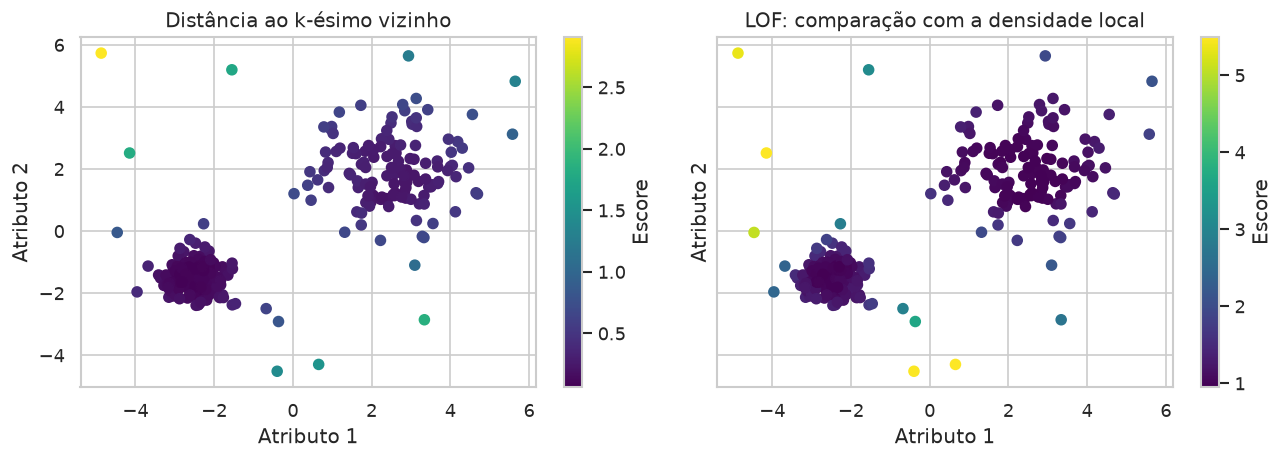

In [4]:
lof = LocalOutlierFactor(n_neighbors=K_VIZINHOS, contamination="auto")
lof.fit_predict(X_pad)
dados["escore_lof"] = -lof.negative_outlier_factor_

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, coluna, titulo in zip(
    axes,
    ["escore_knn", "escore_lof"],
    ["Distância ao k-ésimo vizinho", "LOF: comparação com a densidade local"],
):
    pontos = ax.scatter(X[:, 0], X[:, 1], c=dados[coluna], cmap="viridis", s=35)
    ax.set(title=titulo, xlabel="Atributo 1", ylabel="Atributo 2")
    fig.colorbar(pontos, ax=ax, label="Escore")
fig.tight_layout()
plt.show()

## 4. Ruído no DBSCAN

O DBSCAN marca como ruído objetos que não são pontos centrais nem alcançáveis por densidade a partir deles. Isso fornece uma decisão binária dependente de `eps`, `min_samples`, escala e métrica. O rótulo `-1` significa que o objeto ficou fora das regiões densas sob esses parâmetros; não identifica sua causa nem garante que seja erro.

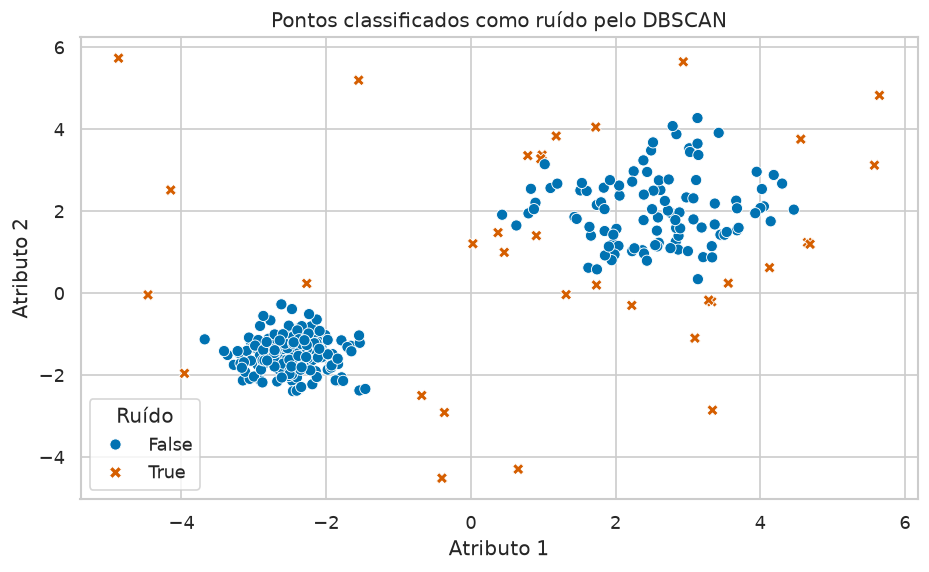

In [5]:
dbscan = DBSCAN(eps=0.28, min_samples=8).fit(X_pad)
dados["alerta_dbscan"] = dbscan.labels_ == -1

ax = sns.scatterplot(
    data=dados, x="atributo_1", y="atributo_2",
    hue="alerta_dbscan", style="alerta_dbscan",
    palette={False: "#0072B2", True: "#D55E00"}, s=45,
)
ax.set(title="Pontos classificados como ruído pelo DBSCAN", xlabel="Atributo 1", ylabel="Atributo 2")
ax.legend(title="Ruído")
plt.show()

## 5. Evidência baseada em agrupamento

Uma estratégia baseada em agrupamento pode sinalizar grupos muito pequenos ou objetos distantes do representante do próprio grupo. Para o k-means, usaremos a distância ao centroide atribuído e uma cerca específica por grupo. Isso evita comparar diretamente as distâncias de um grupo compacto às de um grupo disperso, mas ainda herda as hipóteses geométricas do k-means.

In [6]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE).fit(X_pad)
rotulos_kmeans = kmeans.labels_
distancia_centroide = np.linalg.norm(X_pad - kmeans.cluster_centers_[rotulos_kmeans], axis=1)
dados["grupo_kmeans"] = rotulos_kmeans
dados["distancia_centroide"] = distancia_centroide
limites_grupo = dados.groupby("grupo_kmeans")["distancia_centroide"].quantile(0.95)
dados["alerta_kmeans"] = dados.apply(
    lambda linha: linha["distancia_centroide"] > limites_grupo.loc[linha["grupo_kmeans"]],
    axis=1,
)
display(pd.DataFrame({"limite_p95": limites_grupo, "tamanho": dados.groupby("grupo_kmeans").size()}))

,limite_p95,tamanho
grupo_kmeans,,
0,1.196907,130
1,0.606806,188


## 6. Avaliar com orçamento de investigação

Quando existe um orçamento para investigar $B$ casos, métodos com escore podem ser comparados nos $B$ primeiros. Definimos

$$Precisão@B=\frac{\text{anomalias confirmadas entre os }B\text{ alertas}}{B}.$$

A revocação mede a fração das anomalias conhecidas encontrada. Neste exemplo didático, $B=18$ coincide com a quantidade real, mas aplicações não conhecem esse número antecipadamente. Rótulos obtidos somente nos casos investigados causam viés de verificação: não se sabe quantas anomalias ficaram fora da lista.

In [7]:
ORCAMENTO = 18

def selecionar_top(escores: pd.Series, quantidade: int) -> np.ndarray:
    """Retorna vetor binário com os maiores escores priorizados."""
    selecionados = escores.nlargest(quantidade).index
    alertas = np.zeros(len(escores), dtype=int)
    alertas[selecionados] = 1
    return alertas

predicoes = {
    "k-vizinhos (top 18)": selecionar_top(dados["escore_knn"], ORCAMENTO),
    "LOF (top 18)": selecionar_top(dados["escore_lof"], ORCAMENTO),
    "DBSCAN (ruído)": dados["alerta_dbscan"].astype(int).to_numpy(),
    "k-means (p95 por grupo)": dados["alerta_kmeans"].astype(int).to_numpy(),
}
metricas = []
for metodo, previsto in predicoes.items():
    metricas.append({
        "método": metodo,
        "alertas": int(previsto.sum()),
        "precisão": precision_score(y_referencia, previsto, zero_division=0),
        "revocação": recall_score(y_referencia, previsto, zero_division=0),
    })
metricas = pd.DataFrame(metricas)
display(metricas.round(3))

,método,alertas,precisão,revocação
0,k-vizinhos (top 18),18,0.667,0.667
1,LOF (top 18),18,0.667,0.667
2,DBSCAN (ruído),34,0.412,0.778
3,k-means (p95 por grupo),17,0.706,0.667


Os métodos podem discordar porque respondem a perguntas distintas. A distância ao vizinho favorece isolamento global; o LOF compara densidades locais; o DBSCAN procura regiões conectadas densas; e a distância ao centroide pressupõe grupos representáveis por médias. Precisão e revocação também mudam com o orçamento e os parâmetros, portanto a tabela não estabelece um vencedor universal.

## 7. Dimensionalidade, escala e mudança

Em muitas dimensões, distâncias podem se concentrar e vizinhanças tornam-se menos informativas. Atributos irrelevantes, duplicados ou em escalas grandes dominam escores. Redução de dimensionalidade pode ajudar, mas também ocultar eventos raros; deve ser ajustada sem vazamento e validada para a finalidade.

Um detector também envelhece. Mudanças de população, processo ou coleta alteram a referência. Monitore distribuição de escores, taxa de alertas, confirmações, subgrupos afetados e capacidade da equipe. Reajustar um limiar apenas para manter uma taxa conveniente pode esconder uma mudança real.

## 8. Atividade integradora: lista priorizada

Uma lista operacional deve conservar identificador, escore, método, razão observável e estado da investigação. Combinar métodos por voto pode aumentar robustez, mas detectores correlacionados não constituem evidências independentes.

In [8]:
dados["top_knn"] = predicoes["k-vizinhos (top 18)"].astype(bool)
dados["top_lof"] = predicoes["LOF (top 18)"].astype(bool)
colunas_voto = ["top_knn", "top_lof", "alerta_dbscan", "alerta_kmeans"]
dados["votos"] = dados[colunas_voto].sum(axis=1)
lista_priorizada = (
    dados.assign(id_observacao=lambda df: "OBS-" + df.index.astype(str).str.zfill(3))
    .sort_values(["votos", "escore_lof"], ascending=False)
    .loc[:, ["id_observacao", "atributo_1", "atributo_2", "votos", "escore_knn", "escore_lof"]]
    .head(12)
)
display(lista_priorizada.round(3))

,id_observacao,atributo_1,atributo_2,votos,escore_knn,escore_lof
314,OBS-314,-4.149,2.514,4,1.815,5.493
308,OBS-308,0.655,-4.298,4,1.539,5.482
313,OBS-313,-0.399,-4.518,4,1.422,5.469
302,OBS-302,-4.870,5.732,4,2.907,5.341
304,OBS-304,-4.463,-0.046,4,0.845,5.067
317,OBS-317,-0.365,-2.916,4,0.823,3.638
305,OBS-305,-1.550,5.194,4,1.760,3.121
312,OBS-312,3.341,-2.859,4,1.860,2.701
310,OBS-310,3.097,-1.100,4,1.065,2.180
311,OBS-311,5.648,4.824,4,1.321,2.105


## 9. Quando usar cada método?

Nenhum detector é universal. Escala, métrica, dimensionalidade, geometria e variação de densidade determinam qual noção de anomalia está sendo operacionalizada.

| Método | Recomendado quando | Evidência produzida | Evite usar isoladamente quando |
|---|---|---|---|
| distância ao $k$-ésimo vizinho | anomalias são pontos globalmente isolados e as regiões normais têm densidades comparáveis | escore contínuo de afastamento da vizinhança | há densidades muito diferentes, alta dimensionalidade, escala inadequada ou forte sensibilidade a $k$ |
| LOF | interessa encontrar pontos menos densos que sua vizinhança local | razão entre densidade do ponto e densidade dos vizinhos | há poucos dados locais, vizinhanças instáveis ou necessidade de comparar escores absolutos entre bases distintas |
| ruído do DBSCAN | dados formam regiões densas de formato não convexo e objetos externos devem ficar sem grupo | rótulo de ruído condicionado a `eps` e `min_samples` | as densidades variam muito, a dimensionalidade é alta ou não há justificativa para os parâmetros |
| distância ao centroide | grupos normais são compactos, aproximadamente convexos e bem representados por médias | afastamento do representante do grupo atribuído | grupos são alongados ou não convexos, há extremos que deslocam centroides ou $k$ é incerto |
| grupo pequeno | o domínio considera segmentos raros uma prioridade legítima de investigação | tamanho e isolamento de uma pequena região | uma minoria legítima pode ser confundida com erro ou risco |
| consenso entre métodos | existe orçamento de investigação e se deseja priorizar casos apoiados por noções diferentes de anomalia | quantidade de métodos concordantes ou ranking combinado | detectores são redundantes, parâmetros foram escolhidos no teste ou o voto é tratado como confirmação |

Use métodos de proximidade ou densidade quando a estrutura local importa; métodos de agrupamento quando existe uma representação defensável dos regimes normais. Em todos os casos, compare parâmetros próximos, examine atributos originais e avalie os alertas segundo capacidade e custo de investigação.

## 10. Atividades

**U07-NB03-V01.** Explique por que LOF pode atribuir escore alto a um ponto próximo de um grupo denso e escore menor a um ponto mais distante que pertence a uma região esparsa.

**U07-NB03-E01.** Considere as distâncias de P a seus quatro vizinhos: 0,4; 0,7; 1,1; 1,6. Calcule $s_k(P)$ para $k=2$ e $k=4$ e interprete a mudança.

**U07-NB03-E02.** Reexecute LOF com 5, 15 e 40 vizinhos. Compare as dez primeiras observações de cada ranking e explique quais alertas são estáveis.

**U07-NB03-E03.** Varie `eps` do DBSCAN entre 0,20, 0,28 e 0,40. Registre número de grupos, alertas, precisão e revocação. Explique por que escolher parâmetros usando os rótulos de teste produziria uma avaliação otimista.

**U07-NB03-E04.** Uma equipe só pode investigar dez casos por semana e confirma rótulos apenas nesses casos. Proponha um protocolo de avaliação e monitoramento que reconheça o viés de verificação.

**U07-NB03-E05.** Produza uma ficha para os cinco primeiros casos da lista priorizada contendo razão do alerta, contexto necessário, decisão provisória e campo de revisão. Não use o rótulo sintético como se estivesse disponível operacionalmente.

## 11. Síntese

- Distância ao $k$-ésimo vizinho mede isolamento segundo escala, métrica e vizinhança.
- LOF compara densidade local e pode lidar melhor com regiões de densidades distintas.
- Ruído do DBSCAN e distância a centroides são evidências dependentes das hipóteses de agrupamento.
- Avaliação deve refletir o orçamento de investigação e reconhecer rótulos ausentes ou seletivos.
- Discordância entre métodos é informação útil; alertas exigem contexto, revisão e monitoramento.

## Referências

- HAN, J.; PEI, J.; TONG, H. *Data Mining: Concepts and Techniques*. 4. ed. Morgan Kaufmann, 2023. Cap. 11.
- BREUNIG, M. M. et al. LOF: identifying density-based local outliers. *Proceedings of ACM SIGMOD*, 2000.
- ESTER, M. et al. A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD*, 1996.
- SCIKIT-LEARN DEVELOPERS. Novelty and outlier detection. Documentação oficial.

Os dados e as figuras deste notebook são sintéticos e autorais.